# Feature Encoding: Discretization & Target Encoding
**Dataset:** UCI Optdigits

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = [f"pixel_{i}" for i in range(64)] + ["target"]

# Load train and test separately - IMPORTANT: never fit any transformer on test data
train = pd.read_csv("../../data/raw/optdigits.tra", header=None, names=cols)
test  = pd.read_csv("../../data/raw/optdigits.tes", header=None, names=cols)

print("Train shape:", train.shape)   # run this code to obtain actual value
print("Test shape:", test.shape)     # run this code to obtain actual value
train.head()

Train shape: (3823, 65)
Test shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [3]:
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder

# --- Step A: discretize pixel intensities (fit on TRAIN ONLY) ---
discretizer = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="uniform")
X_binned = discretizer.fit_transform(train.iloc[:, :64])
X_binned_df = pd.DataFrame(X_binned, columns=[f"{c}_bin" for c in train.columns[:64]])
X_binned_df.head()  # run this code to obtain actual value


c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:331: UserWarning: Feature 0 is constant and will be replaced with 0.
  warnings.warn(
c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:331: UserWarning: Feature 39 is constant and will be replaced with 0.
  warnings.warn(


,pixel_0_bin,pixel_1_bin,pixel_2_bin,pixel_3_bin,pixel_4_bin,pixel_5_bin,pixel_6_bin,pixel_7_bin,pixel_8_bin,pixel_9_bin,...,pixel_54_bin,pixel_55_bin,pixel_56_bin,pixel_57_bin,pixel_58_bin,pixel_59_bin,pixel_60_bin,pixel_61_bin,pixel_62_bin,pixel_63_bin
0,0.0,0.0,1.0,2.0,2.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0
1,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,2.0,2.0,0.0,0.0,0.0
2,0.0,0.0,1.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
4,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,0.0,2.0,2.0,1.0,0.0,0.0


In [4]:
# --- Step B: one-hot encode the target ---
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(train[["target"]])
print("Original target shape:", train[["target"]].shape)  # run this code to obtain actual value
print("One-hot target shape:", y_onehot.shape)             # run this code to obtain actual value
print("Categories:", encoder.categories_)                  # run this code to obtain actual value


Original target shape: (3823, 1)
One-hot target shape: (3823, 10)
Categories: [array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])]


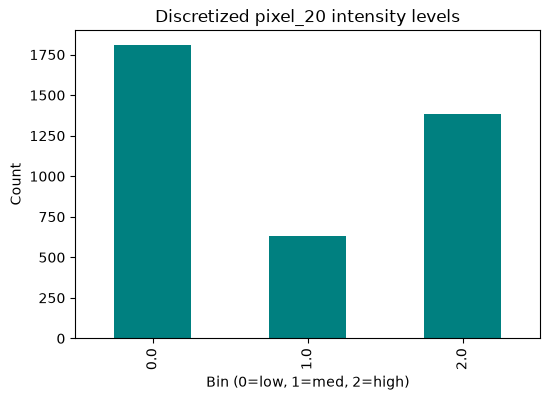

In [ ]:
# --- EDA visualization: binned category counts for one representative pixel ---
plt.figure(figsize=(6,4))
X_binned_df["pixel_20_bin"].value_counts().sort_index().plot(kind="bar", color="teal")
plt.xlabel("Bin (0=low, 1=med, 2=high)"); plt.ylabel("Count")
plt.title("Discretized pixel_20 intensity levels")
plt.savefig("../../results/eda_visualizations/member6_encoding_bins.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Design and Evaluation

Optdigits is a 10-class classification problem with 64 numeric pixel-intensity features. An RBF SVC is suitable for nonlinear class boundaries, while a Random Forest provides a nonlinear, scaling-insensitive comparison. This experiment compares both algorithms on raw pixels, and compares SVC on MinMax-scaled and discretized pixels. `GridSearchCV` tunes each variant using 5-fold stratified cross-validation; each transformation is inside its pipeline so it is refit within every fold. The official test split is held back for the final evaluation. We select the candidate using cross-validation macro F1, then report test accuracy and macro F1. Macro F1 gives each digit class equal weight, while accuracy gives the overall fraction classified correctly.

c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:331: UserWarning: Feature 0 is constant and will be replaced with 0.
  warnings.warn(
c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:331: UserWarning: Feature 39 is constant and will be replaced with 0.
  warnings.warn(
c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:331: UserWarning: Feature 0 is constant and will be replaced with 0.
  warnings.warn(
c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_d

Tuned model comparison (ranked by 5-fold CV macro F1):


,Model variant,CV accuracy,CV macro F1,Test accuracy,Test macro F1,Best parameters
0,SVC - MinMax scaled,0.991106,0.991127,0.979967,0.979877,"{'classifier__C': 10, 'classifier__gamma': 'sc..."
1,SVC - raw pixels,0.990583,0.990607,0.979410,0.979332,"{'classifier__C': 10, 'classifier__gamma': 'sc..."
2,SVC - discretized pixels,0.988490,0.988527,0.978297,0.978262,"{'classifier__C': 10, 'classifier__gamma': 'sc..."
3,Random Forest - raw pixels,0.981427,0.981516,0.972176,0.972161,"{'classifier__max_depth': None, 'classifier__n..."
4,Random Forest - discretized pixels,0.977763,0.977808,0.972732,0.972694,"{'classifier__n_estimators': 200, 'discretizer..."


CV-selected model: SVC - MinMax scaled
Classification report on the held-out official test split:
              precision    recall  f1-score   support

           0     0.9889    1.0000    0.9944       178
           1     0.9679    0.9945    0.9810       182
           2     1.0000    0.9887    0.9943       177
           3     0.9836    0.9836    0.9836       183
           4     0.9945    0.9945    0.9945       181
           5     0.9577    0.9945    0.9757       182
           6     1.0000    0.9890    0.9944       181
           7     0.9940    0.9330    0.9625       179
           8     0.9706    0.9483    0.9593       174
           9     0.9459    0.9722    0.9589       180

    accuracy                         0.9800      1797
   macro avg     0.9803    0.9798    0.9799      1797
weighted avg     0.9803    0.9800    0.9799      1797



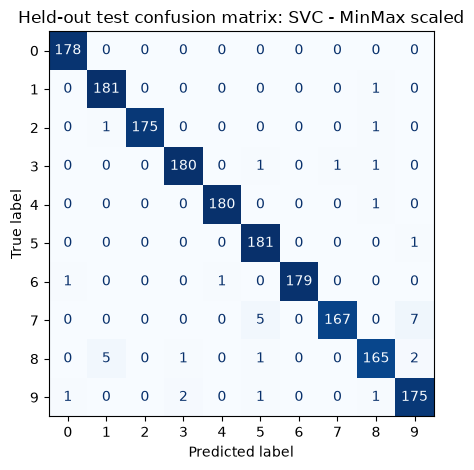

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

feature_cols = [f"pixel_{i}" for i in range(64)]
X_train = train[feature_cols]
y_train = train["target"].astype(int)
X_test = test[feature_cols]
y_test = test["target"].astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
experiments = {
    "SVC - raw pixels": (
        Pipeline([("classifier", SVC())]),
        {"classifier__C": [1, 10], "classifier__gamma": ["scale", 0.01]},
    ),
    "SVC - MinMax scaled": (
        Pipeline([("scaler", MinMaxScaler()), ("classifier", SVC())]),
        {"classifier__C": [1, 10], "classifier__gamma": ["scale", 0.01]},
    ),
    "SVC - discretized pixels": (
        Pipeline([
            ("discretizer", KBinsDiscretizer(encode="ordinal")),
            ("classifier", SVC()),
        ]),
        {
            "discretizer__n_bins": [3, 5],
            "discretizer__strategy": ["uniform", "quantile"],
            "classifier__C": [1, 10],
            "classifier__gamma": ["scale"],
        },
    ),
    "Random Forest - raw pixels": (
        Pipeline([("classifier", RandomForestClassifier(random_state=42, n_jobs=1))]),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 25],
        },
    ),
    "Random Forest - discretized pixels": (
        Pipeline([
            ("discretizer", KBinsDiscretizer(encode="ordinal")),
            ("classifier", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]),
        {
            "discretizer__n_bins": [3, 5],
            "discretizer__strategy": ["uniform", "quantile"],
            "classifier__n_estimators": [100, 200],
        },
    ),
}

fitted_models = {}
comparison_rows = []
for name, (pipeline, parameter_grid) in experiments.items():
    search = GridSearchCV(
        pipeline,
        parameter_grid,
        scoring=scoring,
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_
    best_index = search.best_index_
    test_predictions = search.predict(X_test)
    comparison_rows.append({
        "Model variant": name,
        "CV accuracy": search.cv_results_["mean_test_accuracy"][best_index],
        "CV macro F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, test_predictions),
        "Test macro F1": f1_score(y_test, test_predictions, average="macro"),
        "Best parameters": search.best_params_,
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    "CV macro F1", ascending=False
).reset_index(drop=True)
print("Tuned model comparison (ranked by 5-fold CV macro F1):")
display(comparison)

selected_name = comparison.loc[0, "Model variant"]
selected_model = fitted_models[selected_name]
selected_predictions = selected_model.predict(X_test)
print(f"CV-selected model: {selected_name}")
print("Classification report on the held-out official test split:")
print(classification_report(y_test, selected_predictions, digits=4))

ConfusionMatrixDisplay.from_predictions(
    y_test, selected_predictions, cmap="Blues", colorbar=False
)
plt.title(f"Held-out test confusion matrix: {selected_name}")
plt.tight_layout()
plt.show()

### Results, conclusion, and limitations

The best candidate by cross-validation macro F1 was the MinMax-scaled RBF SVC (CV accuracy 99.11%, CV macro F1 99.11%). On the untouched official test split it achieved 98.00% accuracy and 97.99% macro F1. Raw-pixel SVC was a close second (97.94% test accuracy); discretizing pixels gave a slightly lower SVC score, and both Random Forest variants scored lower. The small scaling gain supports SVC's sensitivity to feature scale, while the Random Forest provides a useful tree-based baseline that does not depend on scaling.

The confusion matrix shows 36 errors among 1,797 test digits. Recall was lowest for digit 7 (93.3%) and digit 8 (94.8%); notable confusions include 7 as 9 (7 cases) and 8 as 1 (5 cases). This is consistent with visually similar handwritten shapes. Accuracy and macro F1 are close because the test examples are distributed fairly evenly across the ten classes.

Limitations: the parameter grids are deliberately small, the official test set is a single fixed evaluation split, and 8x8 pixel summaries cannot retain all handwriting detail. Improvements could include a wider SVC C/gamma search on training folds, HOG or other stroke-shape features, and repeated stratified validation or nested CV for a less split-sensitive estimate. Do not tune against the official test scores.

### Viva summary

Explain the RBF kernel as allowing nonlinear decision boundaries between digit classes. Describe `GridSearchCV` as trying parameter combinations over stratified folds, with macro F1 used to select the best candidate. Compare the five variants by their CV macro F1 first and use test accuracy/macro F1 only as final generalization checks. Discretization slightly reduced SVC performance relative to continuous scaled pixels, showing that binning may discard useful intensity detail. The held-out test split must not be used to choose parameters.